# Обнаружение объектов с использованием YOLO

## 1. Что такое обнаружение объектов?

**Обнаружение (детектирование, детекция) объектов (object detection)** — это задача компьютерного зрения, в которой требуется:
- определить **наличие** объектов интересующих классов на изображении,
- **локализовать** каждый объект с помощью ограничивающего прямоугольника (**bounding box**),
- **классифицировать** каждый объект (например, «человек», «машина», «собака»).

В отличие от **классификации изображений** (где всё изображение относится к одному классу) и **сегментации** (где требуется точная маска объекта), детекция даёт **координаты и класс** для каждого найденного объекта.

---

## 2. Подходы к детекции объектов

Существует два основных типа архитектур:

### 2.1. Двухэтапные детекторы (Two-stage detectors)
- Сначала генерируют **предложения регионов** (region proposals), где могут находиться объекты.
- Затем классифицируют каждый регион.
- Пример: **R-CNN**, **Fast R-CNN**, **Faster R-CNN**.
- **Преимущества**: высокая точность.  
- **Недостатки**: медленная работа, сложная архитектура.

### 2.2. Одноэтапные детекторы (One-stage detectors)
- Выполняют детекцию **за один проход** нейросети.
- Примеры: **YOLO**, **SSD (Single Shot MultiBox Detector)**, **RetinaNet**.
- **Преимущества**: высокая скорость, подходят для реального времени.  
- **Недостатки**: иногда уступают в точности двухэтапным моделям (особенно на мелких объектах).

---

## 3. Что такое YOLO?

**YOLO (You Only Look Once)** — семейство одноэтапных нейросетевых моделей для детекции объектов, впервые предложенное Джозефом Редмоном в 2016 году.

### Основная идея:
- Всё изображение подаётся в сеть **один раз**.
- Выходная сетка (например, 13×13) делит изображение на ячейки.
- Каждая ячейка предсказывает:
  - несколько **ограничивающих рамок** (обычно 2–3),
  - **вероятность наличия объекта** в рамке,
  - **уверенность в классе** (class confidence).

Таким образом, YOLO **одновременно** решает задачи локализации и классификации.

---

## 4. Эволюция YOLO

| Версия | Год | Особенности |
|--------|-----|-------------|
| YOLOv1 | 2016 | Первая версия, простая, но низкая точность на мелких объектах |
| YOLOv2 / YOLO9000 | 2017 | Anchor boxes, batch normalization, multi-scale training |
| YOLOv3 | 2018 | Feature Pyramid Network (FPN)-подобная архитектура, лучше детектирует мелкие объекты |
| YOLOv4 | 2020 | Оптимизация под GPU, CSPDarknet, PANet, Mish-активация |
| YOLOv5 | 2020 | Разработана компанией Ultralytics (неофициальная), удобная для PyTorch |
| YOLOv6 | 2022 | Разработана Meituan, ориентирована на промышленное применение |
| YOLOv7 | 2022 | Улучшенная эффективность и точность |
| **YOLOv8** | **2023** | Поддержка детекции, сегментации, поз-оценки, классификации; огромное сообщество |
| YOLO11 | 2024 | Преемник YOLOv8 от Ultralytics: выше точность при меньшем числе параметров |

> 💡 В нашем занятии используется **YOLOv8** от **Ultralytics** — современная, легко устанавливаемая и документированная реализация. Вышедшая позже YOLO11 ещё не вытеснила v8 — она по-прежнему повсеместно используется и отлично документирована.

---

## 5. Архитектура YOLOv8 (упрощённо)

YOLOv8 состоит из трёх основных компонентов:

1. **Backbone** — извлекает признаки из изображения (используется модифицированная CSPDarknet).
2. **Neck** — объединяет признаки разных масштабов (аналог FPN + PANet).
3. **Head** — предсказывает bounding boxes, классы и (опционально) маски сегментации.

YOLOv8 **не использует anchor boxes** (в отличие от YOLOv3/v4/v5), что упрощает обучение и повышает гибкость.

---

## 6. Формат выходных данных YOLO

Для каждого обнаруженного объекта модель возвращает:
- **Координаты bounding box**: `(x_center, y_center, width, height)` в нормализованных координатах (от 0 до 1).
- **Класс объекта**: индекс из списка классов (например, 0 = «человек», 2 = «машина»).
- **Уверенность (confidence)**: вероятность того, что в рамке действительно находится объект.

> В датасете **COCO**, на котором предобучена YOLOv8, **80 классов**.

---

## 7. Преимущества YOLO

- **Высокая скорость**: до 100+ FPS на современных GPU (в зависимости от размера модели).
- **Хороший баланс точности и скорости**.
- **Простота интеграции**: благодаря библиотеке Ultralytics.
- **Поддержка множества задач**: детекция, сегментация, pose estimation, классификация.

---

## 8. Ограничения YOLO

- Может пропускать **очень мелкие или плотно сгруппированные объекты**.
- Точность зависит от **качества обучающих данных**.
- Требует **GPU для быстрой работы** (хотя лёгкие версии, например `yolov8n`, работают и на CPU).

---

## 9. Практическое применение YOLO

YOLO используется в:
- системах видеонаблюдения (обнаружение людей, транспорта),
- автономных автомобилях (детекция пешеходов, знаков),
- ритейле (подсчёт посетителей, распознавание товаров),
- дрон-инспекции (поиск дефектов, животных),
- медицине (локализация патологий на снимках).

---

## 10. Важные понятия

| Термин | Определение |
|--------|-------------|
| **Bounding box** | Прямоугольник, ограничивающий объект на изображении |
| **Confidence score** | Мера уверенности модели в том, что объект действительно присутствует |
| **IoU (Intersection over Union)** | Метрика перекрытия предсказанной и истинной рамок (используется при обучении и NMS) |
| **NMS (Non-Maximum Suppression)** | Алгоритм удаления дублирующих рамок вокруг одного объекта |
| **COCO dataset** | Стандартный датасет для задач детекции (80 классов, >200k изображений) |

---

статья про историю YOLO: https://habr.com/ru/articles/865834/

In [1]:
# Установка (при первом запуске ultralytics подтянет PyTorch, если его нет)
%pip install ultralytics opencv-python matplotlib

/home/roma/PycharmProjects/university/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

In [3]:
# Загружаем предобученную модель: yolov8n — "nano", самая лёгкая (~6 МБ).
# Файл yolov8n.pt лежит рядом с ноутбуком; если его нет — скачается из интернета.
model = YOLO('yolov8n.pt')

print("Число классов COCO:", len(model.names))

Число классов COCO: 80


| Модель     | Название файла   | Параметры (млн) | Размер файла | Точность (mAP@0.5:0.95) | Скорость |
|------------|------------------|------------------|--------------|--------------------------|----------|
| YOLOv8n    | `yolov8n.pt`     | ~3.2             | ~6 MB        | ~37.3                    | ⚡️ Самая быстрая |
| YOLOv8s    | `yolov8s.pt`     | ~11.2            | ~22 MB       | ~44.9                    | 🚀 Быстрая |
| YOLOv8m    | `yolov8m.pt`     | ~25.9            | ~52 MB       | ~50.2                    | ⏱️ Средняя |
| YOLOv8l    | `yolov8l.pt`     | ~43.7            | ~87 MB       | ~52.9                    | 🐢 Медленная |
| YOLOv8x    | `yolov8x.pt`     | ~68.2            | ~137 MB      | ~53.9                    | 🐌 Самая медленная |


image 1/1 /home/roma/PycharmProjects/university/recogn_generate_image/task_9/zidane.jpg: 384x640 2 persons, 1 tie, 49.8ms
Speed: 7.9ms preprocess, 49.8ms inference, 2.1ms postprocess per image at shape (1, 3, 384, 640)


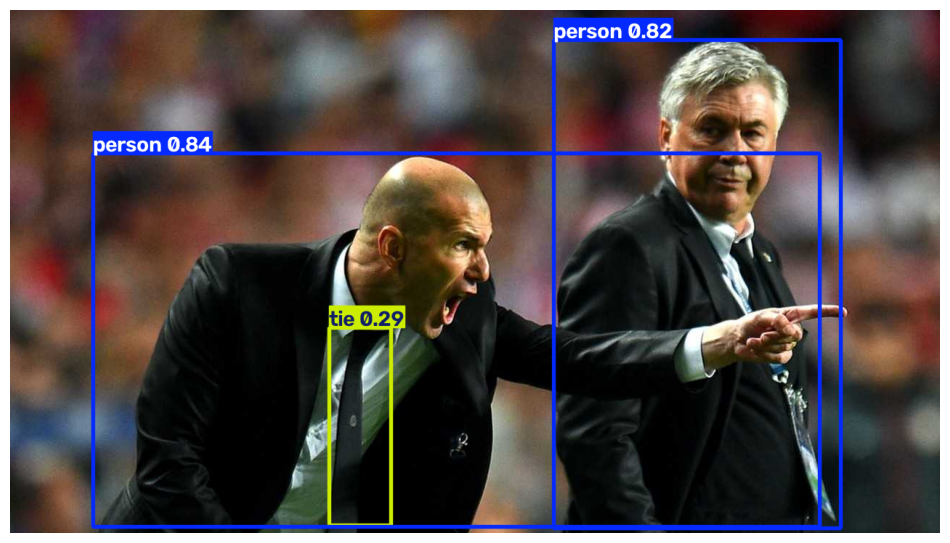

In [4]:
# Тестовое изображение: zidane.jpg лежит рядом с ноутбуком.
# Используем локальный файл, чтобы не зависеть от интернета.
img_path = 'zidane.jpg'

# Выполняем инференс
results = model(img_path)

# Визуализация результата
res_plotted = results[0].plot()  # возвращает изображение с bounding boxes

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [5]:
# Выведем информацию о найденных объектах
boxes = results[0].boxes
for box in boxes:
    cls = int(box.cls[0])        # индекс класса
    conf = float(box.conf[0])    # уверенность
    label = model.names[cls]     # имя класса
    print(f"Обнаружен объект: {label}, уверенность: {conf:.2f}")

Обнаружен объект: person, уверенность: 0.84
Обнаружен объект: person, уверенность: 0.82
Обнаружен объект: tie, уверенность: 0.29


### Порог уверенности (conf)

По умолчанию YOLO отбрасывает детекции с уверенностью ниже `conf=0.25`.
Поэтому в результат попал и «tie» (галстук) с 0.29 — модель в нём почти не уверена.
Поднимем порог и посмотрим, что изменится.

In [6]:
results_strict = model('zidane.jpg', conf=0.5)

for box in results_strict[0].boxes:
    label = model.names[int(box.cls[0])]
    conf = float(box.conf[0])
    print(f"Обнаружен объект: {label}, уверенность: {conf:.2f}")

# «tie» с 0.29 исчез: порог отфильтровал сомнительную детекцию.
# Слишком высокий порог — теряем настоящие объекты; слишком низкий — получаем ложные рамки.


image 1/1 /home/roma/PycharmProjects/university/recogn_generate_image/task_9/zidane.jpg: 384x640 2 persons, 34.2ms
Speed: 10.4ms preprocess, 34.2ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)
Обнаружен объект: person, уверенность: 0.84
Обнаружен объект: person, уверенность: 0.82


### Подсчёт объектов по классам

{'person': 2, 'tie': 1}


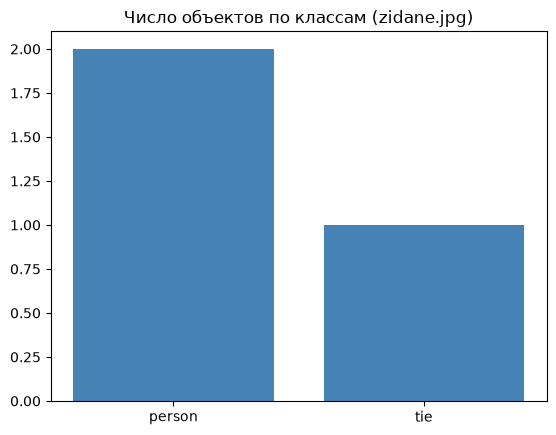

In [7]:
from collections import Counter

# Сколько объектов каждого класса найдено на изображении
counts = Counter(model.names[int(c)] for c in results[0].boxes.cls)
print(dict(counts))

plt.bar(counts.keys(), counts.values(), color='steelblue')
plt.title('Число объектов по классам (zidane.jpg)')
plt.show()

### Детекция на видео

Обработка видео кадр за кадром. Важные моменты:

* `stream=True` — результаты выдаются генератором кадр за кадром, а не копятся в памяти
  (без этого длинное видео может переполнить RAM — об этом предупреждает сам Ultralytics);
* `verbose=False` — отключает построчный лог на каждый кадр;
* `save=True` — результат сохраняется в папку `runs/detect/custom_video/`:
  откройте получившийся видеофайл плеером после выполнения ячейки.

Заодно соберём статистику по кадрам и построим график «число объектов по кадрам» —
упрощённый аналог отслеживания (tracking), о котором шла речь в занятии 1.
Полноценный трекинг с ID объектов: `model.track(source=..., persist=True, stream=True)`.

In [8]:
import time
from collections import Counter

video_path = 'person-bicycle-car-detection.mp4'

t0 = time.time()
frames = model.predict(source=video_path, stream=True, save=True,
                       project='runs/detect', name='custom_video',
                       exist_ok=True, verbose=False)

frame_stats = [Counter(r.boxes.cls.int().tolist()) for r in frames]
n = len(frame_stats)
dt = time.time() - t0
print(f"Кадров обработано: {n}; время: {dt:.1f} с ({n/dt:.1f} кадров/с)")

# Куда сохранился результат:
import glob
print("Результат видео:", *glob.glob('runs/detect/custom_video/*'))

Results saved to /home/roma/PycharmProjects/university/runs/detect/runs/detect/custom_video
Кадров обработано: 647; время: 33.0 с (19.6 кадров/с)
Результат видео:


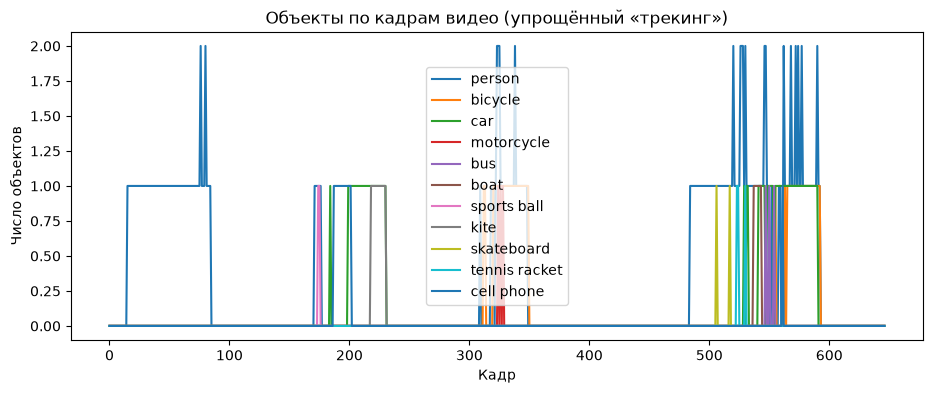

In [9]:
# Число объектов каждого класса по кадрам
seen = sorted({c for f in frame_stats for c in f})

plt.figure(figsize=(11, 4))
for cid in seen:
    plt.plot([f.get(cid, 0) for f in frame_stats], label=model.names[cid])
plt.xlabel('Кадр')
plt.ylabel('Число объектов')
plt.title('Объекты по кадрам видео (упрощённый «трекинг»)')
plt.legend()
plt.show()

# Вопросы: почему детекции появляются и исчезают? Почему часть кадров пустая?
# (объект ушёл из кадра / стал слишком мелким / размыт при движении)

---

## Индивидуальные задания

1. Прогнать `yolov8n` и `yolov8s` на одном фото: сравнить число детекций, уверенности и время инференса (оно печатается в выводе). Стоит ли прирост точности утроенного размера модели?

2. Своё фото с телефона: какие объекты нашлись? Что из кадра **не** нашлось и почему? (главная причина — класса нет среди 80 классов COCO)

3. Для своей фотографии построить bar-chart «число объектов по классам» (`Counter` + `plt.bar`, как в ячейке выше).

4. *(Дополнительно)* Взять один кадр видео и прогнать его с порогами `conf=0.1 / 0.3 / 0.6`: как меняется число рамок? Появляются ли ложные срабатывания при низком пороге?

---

## 📝 Задания для самостоятельной работы

1. **«Почти-трекинг»**: обработать видео со `stream=True`, построить график числа объектов по классам по кадрам (как в ячейке выше) и объяснить провалы — уход объекта из кадра, мелкий размер, размытие. *Рядом с ноутбуком лежит готовый скрипт `yolo_video_detect.py` — сравните, как та же задача оформляется отдельной программой.*

2. **Настоящий трекинг**: `model.track(source='person-bicycle-car-detection.mp4', persist=True, stream=True)` — собрать уникальные ID объектов. Сколько разных людей прошло через кадр?

3. **Веб-камера**: `model(source=0, show=True)` — детекция в реальном времени (если есть возможность).



### Задание 1. `yolov8n` vs `yolov8s` на одном фото

yolov8n: детекций=3, средняя уверенность=0.65, время инференса=47 мс
yolov8s: детекций=3, средняя уверенность=0.83, время инференса=116 мс


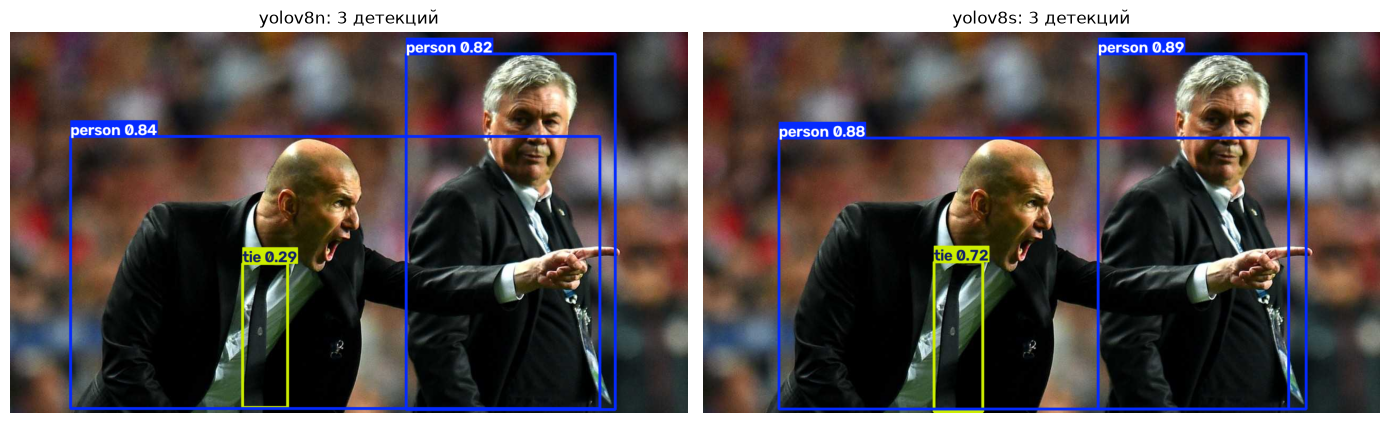

In [10]:
import time

model_n = YOLO('yolov8n.pt')
model_s = YOLO('yolov8s.pt')

# Прогрев: первый вызов включает загрузку весов и подготовку,
# поэтому время инференса честно мерить со второго вызова
model_n('zidane.jpg', verbose=False)
model_s('zidane.jpg', verbose=False)

stats = {}
for name, m in [('yolov8n', model_n), ('yolov8s', model_s)]:
    t0 = time.perf_counter()
    r = m('zidane.jpg', verbose=False)[0]
    dt = (time.perf_counter() - t0) * 1000

    boxes = r.boxes
    confs = [float(c) for c in boxes.conf]
    stats[name] = r
    print(f"{name}: детекций={len(boxes)}, "
          f"средняя уверенность={sum(confs)/len(confs):.2f}, "
          f"время инференса={dt:.0f} мс")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, r) in zip([ax1, ax2], stats.items()):
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{name}: {len(r.boxes)} детекций')
    ax.axis('off')
plt.tight_layout()
plt.show()


### Задание 2. Своё фото с телефона: что нашлось, а что нет



image 1/1 /home/roma/PycharmProjects/university/recogn_generate_image/task_9/img.png: 544x640 1 person, 71.2ms
Speed: 1.3ms preprocess, 71.2ms inference, 0.8ms postprocess per image at shape (1, 3, 544, 640)


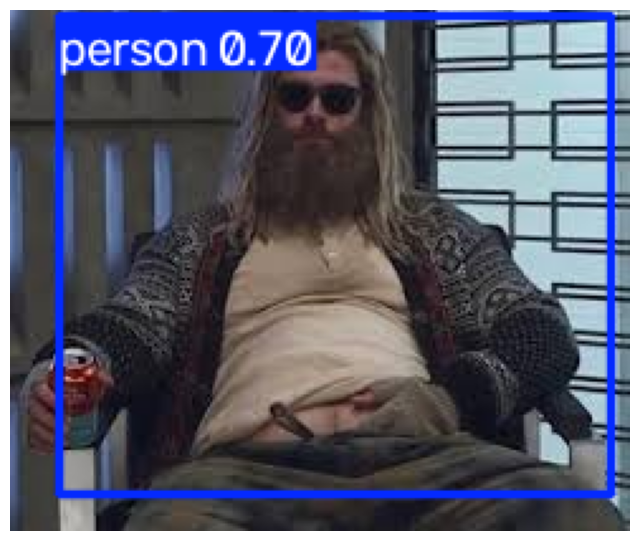

Обнаружен объект: person, уверенность: 0.70


In [11]:
my_img = '01_list_system.png'

results_my = model(my_img, conf=0.25)[0]

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(results_my.plot(), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

for box in results_my.boxes:
    label = model.names[int(box.cls[0])]
    conf = float(box.conf[0])
    print(f"Обнаружен объект: {label}, уверенность: {conf:.2f}")


### Задание 3. Bar-chart «число объектов по классам» для своего фото

{'person': 1}


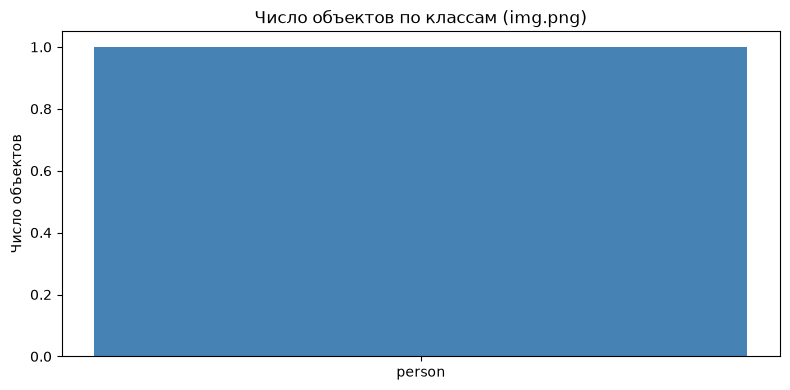

In [12]:
from collections import Counter

counts_my = Counter(model.names[int(c)] for c in results_my.boxes.cls)
print(dict(counts_my))

plt.figure(figsize=(8, 4))
plt.bar(counts_my.keys(), counts_my.values(), color='steelblue')
plt.title('Число объектов по классам (01_list_system.png)')
plt.ylabel('Число объектов')
plt.tight_layout()
plt.show()

### Задание 4. *(Дополнительно)* Один кадр видео с порогами `conf=0.1 / 0.3 / 0.6`



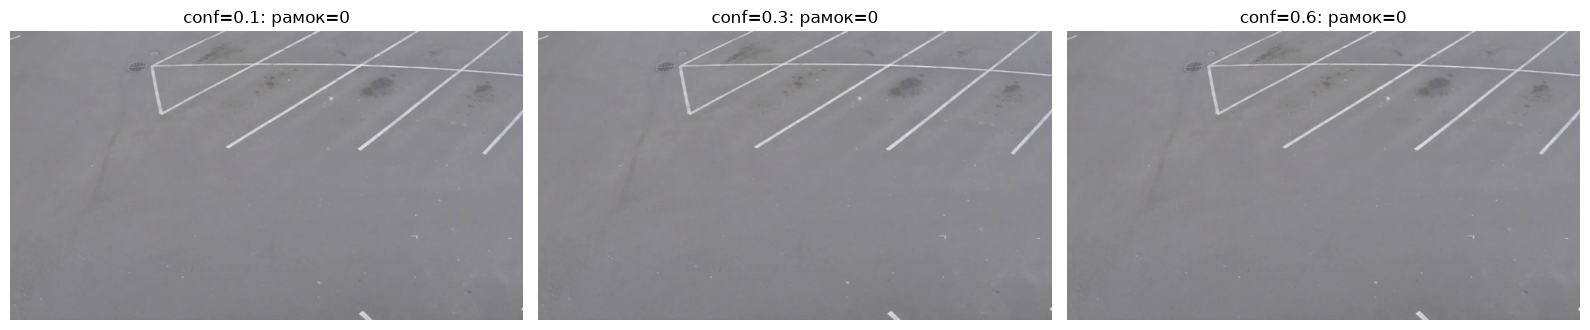

In [13]:
# Извлекаем первый кадр видео
cap = cv2.VideoCapture('person-bicycle-car-detection.mp4')
ret, first_frame = cap.read()
cap.release()
assert ret, 'Не удалось прочитать кадр из видео'
cv2.imwrite('first_frame.jpg', first_frame)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, conf in zip(axes, [0.1, 0.3, 0.6]):
    r = model(first_frame, conf=conf, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'conf={conf}: рамок={len(r.boxes)}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Самостоятельная 1. «Почти-трекинг»: объекты по кадрам видео

Обработано кадров: 120


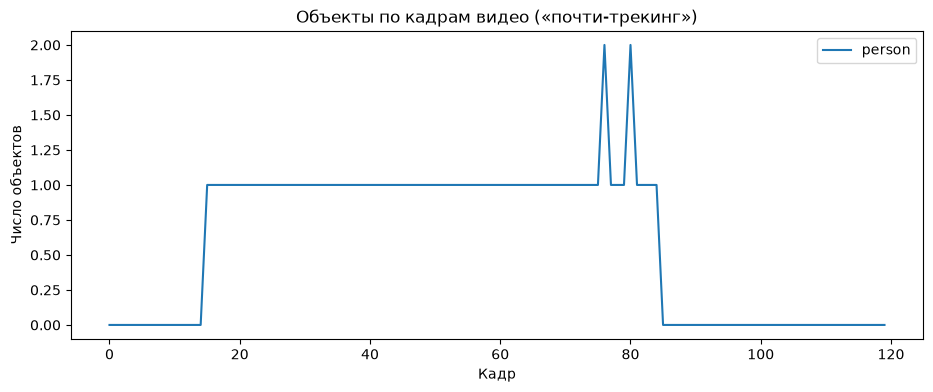

In [14]:
# stream=True — результаты выдаются генератором кадр за кадром, не копясь в памяти
frames_iter = model.predict(source='person-bicycle-car-detection.mp4',
                            stream=True, verbose=False)

frame_stats_short = []
for i, r in enumerate(frames_iter):
    frame_stats_short.append(Counter(r.boxes.cls.int().tolist()))
    if i >= 119:   # ограничиваем 120 кадрами, чтобы ячейка считалась быстро
        break
print(f"Обработано кадров: {len(frame_stats_short)}")

seen = sorted({c for f in frame_stats_short for c in f})
plt.figure(figsize=(11, 4))
for cid in seen:
    plt.plot([f.get(cid, 0) for f in frame_stats_short], label=model.names[cid])
plt.xlabel('Кадр')
plt.ylabel('Число объектов')
plt.title('Объекты по кадрам видео («почти-трекинг»)')
plt.legend()
plt.show()

### Самостоятельная 2. Настоящий трекинг: уникальные ID объектов

`model.track(..., persist=True)` присваивает каждому объекту устойчивый ID между кадрами — собираем уникальные ID и считаем разных людей.

In [15]:
# Настоящий трекинг: persist=True заставляет трекер помнить объекты между кадрами
track_iter = model.track(source='person-bicycle-car-detection.mp4',
                         persist=True, stream=True, verbose=False)

unique_ids = {}   # class -> множество уникальных ID
frames_with_ids = 0
for r in track_iter:
    if r.boxes.id is not None:
        frames_with_ids += 1
        for cls, tid in zip(r.boxes.cls.int().tolist(), r.boxes.id.int().tolist()):
            unique_ids.setdefault(cls, set()).add(tid)

print(f"Кадров с треками: {frames_with_ids}")
for cid in sorted(unique_ids):
    print(f"{model.names[cid]:12s} уникальных объектов: {len(unique_ids[cid])}")

n_people = len(unique_ids.get(0, set()))   # класс 0 в COCO — person
print(f"\nРазных людей прошло через кадр: {n_people}")

KeyboardInterrupt: 